# Building a Dataset Using XArray

In the previous notebook, you learned how to make `DataArray`s with Xarray. But Xarray has another level of organization, referred to as a `Dataset`, which is a collection of DataArrays.
  - The `DataArray`: A multidimensional array with labels describing each of its dimensions.
  - The `Dataset`: A collection of `DataArrays` and their relationships.

We'll be working with a good amount of data organized in `Xarray`, mainly to load data, select the variables we're interested in, and convert the data into the structure we want, so let's take a little time to familiarize ourselves with some of these features

## Setup

### Import Libraries

In [3]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

## Creating a Dataset from DataArrays

You already know how to create an `xr.DataArray`. A `Dataset` combines several named DataArrays into one object. **Dimensions** describe the axes of each variable; **coordinates** provide labels for positions along those axes. Variables can share dimensions and coordinates without having the same shape.

Let's build a miniature behavioral experiment before examining the real recording.

**Example:** We measured reaction time and stimulus contrast over four trials. Create two DataArrays using the **same** `trial` coordinate.

In [4]:
trials = [10, 11, 12, 13]

reaction_time = xr.DataArray(
    [0.42, 0.35, 0.51, 0.39],
    dims=['trial'],
    coords={'trial': trials},
    name='reaction_time',
)

contrast_left = xr.DataArray(
    [0.0, 0.5, 1.0, 0.5],
    dims=['trial'],
    coords={'trial': trials},
    name='contrast_left',
)

reaction_time

<xarray.DataArray 'reaction_time' (trial: 4)> Size: 32B
array([0.42, 0.35, 0.51, 0.39])
Coordinates:
  * trial    (trial) int64 32B 10 11 12 13

**Example:** Combine the DataArrays into a Dataset. Dictionary keys become the variable names. Notice that `trial` appears **once** as a shared coordinate, while both measurements are separate data variables.

In [ ]:
experiment = xr.Dataset({
    'reaction_time': reaction_time,
    'contrast_left': contrast_left,
})
experiment

<xarray.Dataset> Size: 96B
Dimensions:        (trial: 4)
Coordinates:
  * trial          (trial) int64 32B 10 11 12 13
Data variables:
    reaction_time  (trial) float64 32B 0.42 0.35 0.51 0.39
    contrast_left  (trial) float64 32B 0.0 0.5 1.0 0.5

**Exercise:** Add a `response_type` DataArray with the values `['left', 'right', 'right', 'left']`, indexed by the same trials. Then add it to the Dataset and inspect `experiment`.

*Hint:* A Dataset can be extended just like a dictionary: `experiment['response_type'] = ...`.

In [ ]:
response_type = xr.DataArray(
    ['left', 'right', 'right', 'left'],
    dims=['trial'],
    coords={'trial': trials},
)
experiment['response_type'] = response_type
experiment

<xarray.Dataset> Size: 176B
Dimensions:        (trial: 4)
Coordinates:
  * trial          (trial) int64 32B 10 11 12 13
Data variables:
    reaction_time  (trial) float64 32B 0.42 0.35 0.51 0.39
    contrast_left  (trial) float64 32B 0.0 0.5 1.0 0.5
    response_type  (trial) <U5 80B 'left' 'right' 'right' 'left'

### Different dimensions, same Dataset

Suppose we also measured pupil size at three time points during each trial. This variable has **two dimensions**, `trial` and `time`. The other variables only have `trial`. They can all live in the same Dataset because the shared `trial` axis refers to the same trials.

**Example:** Create the pupil-size DataArray and add it to `experiment`. Examine the Dataset's dimensions, coordinates, and data variables.

In [ ]:
pupil_size = xr.DataArray(
    [[2.1, 2.3, 2.2],
     [2.0, 2.2, 2.4],
     [2.3, 2.4, 2.5],
     [2.2, 2.1, 2.3]],
    dims=['trial', 'time'],
    coords={'trial': trials, 'time': [0.0, 0.5, 1.0]},
)
experiment['pupil_size'] = pupil_size
experiment

**Exercise:** Select trial `12` from the *whole Dataset* using `.sel(trial=12)`. Which measurements are returned? Then select the pupil measurements at time `0.5` for **all trials**.

Notice that coordinate labels (such as trial `12`) are not necessarily the same as positional indices.

In [ ]:
experiment.sel(trial=12)

**Key idea:** Matching dimension names tell Xarray which axes are related; coordinate labels tell it *which observations correspond*. If labels differ, Xarray may reorder, align, or introduce missing values, depending on the operation. Always inspect the coordinates when combining data.

Now look for these same relationships in the real Steinmetz Dataset below: some variables describe trials, some describe cells, and `spike_count` spans cells, trials, and time.

## Working with XArray Datasets

Datasets describe the relationships between multiple data variables, often connected by their coordinates.  For example, there could be different behavioral measurements taken at the same time points, or different data might be related to the same subject.  `xr.Dataset` objects help in this way to describe a more-complete picture of an experiment.

Let's explore Datasets by looking at the data from a session of the [Steinmetz et al, 2019 paper](https://www.nature.com/articles/s41586-019-1787-x). In this notebook, we'll be exploring the spike counts data recorded during a specific session and investigate differences between brain regions and their relation to behavioral, task, or performance variables.  This data, stored in the netCDF format (the `.nc` extension), can be loaded as an XArray Dataset.

| Code | Description |
|---|---|
| `xr.load_dataset("file.nc")` | Load a netCDF file as an XArray Dataset. |
| `dset['variable_name']` | Access a specific variable (DataArray) from the dataset. |
| `dset[['var1', 'var2']]` | Access multiple variables from the dataset simultaneously. |
| `dset['variable'].loc[start:end]` | Select data using location-based indexing for specific range. |
| `sum(boolean_array).item()` | Count True values in boolean array and extract as scalar. |
| `len(array)` | Get the length of an array. |

Run the following code cell to load the dataset into Python using XArray. Explore the dataset. Note that different variables are related to different sets of coordinates:

#### **Exercises**

In [3]:
dset = xr.load_dataset(f"data/steinmetz_2017-12-05_Lederberg.nc")
dset

<xarray.Dataset> Size: 125MB
Dimensions:             (trial: 340, time: 250, cell: 698, sample: 82,
                         waveform_component: 3, probe: 384, brain_area_lfp: 12,
                         spike_id: 3185888)
Coordinates:
  * trial               (trial) int32 1kB 1 2 3 4 5 6 ... 336 337 338 339 340
  * time                (time) float64 2kB 0.01 0.02 0.03 0.04 ... 2.48 2.49 2.5
  * cell                (cell) int32 3kB 1 2 3 4 5 6 ... 693 694 695 696 697 698
  * waveform_component  (waveform_component) int32 12B 1 2 3
  * probe               (probe) int32 2kB 1 2 3 4 5 6 ... 380 381 382 383 384
  * brain_area_lfp      (brain_area_lfp) <U5 240B 'DG' 'LGd' ... 'MD' 'VISam'
  * spike_id            (spike_id) int32 13MB 1 2 3 ... 3185886 3185887 3185888
Dimensions without coordinates: sample
Data variables: (12/31)
    contrast_left       (trial) int8 340B 0 0 0 100 25 50 0 0 ... 0 0 0 0 0 0 0
    contrast_right      (trial) int8 340B 0 0 0 50 50 50 ... 100 100 100 100 100
    gocue               (trial) float64 3kB 0.4884 0.5617 ... 0.7894 0.7892
    stim_onset          (trial) float64 3kB 0.5 0.5 0.5 0.5 ... 0.5 0.5 0.5 0.5
    feedback_type       (trial) float64 3kB 1.0 -1.0 1.0 1.0 ... -1.0 -1.0 -1.0
    feedback_time       (trial) float64 3kB 2.028 0.9821 2.175 ... 2.331 2.316
    ...                  ...
    waveform_w          (cell, sample, waveform_component) float32 687kB 0.0 ...
    waveform_u          (cell, waveform_component, probe) float32 3MB 0.0 ......
    lfp                 (brain_area_lfp, trial, time) float64 8MB -57.29 ... ...
    spike_time          (spike_id) float32 13MB 0.01967 0.09227 ... 2.355 2.475
    spike_cell          (spike_id) uint32 13MB 1 1 1 1 1 ... 698 698 698 698 698
    spike_trial         (spike_id) uint32 13MB 1 1 1 1 1 ... 450 450 450 450 450

**Example**: Get the reaction time for each trial in the session.

In [4]:
dset['reaction_time']

<xarray.DataArray 'reaction_time' (trial: 340)> Size: 3kB
array([ 740.,  160.,  730.,  210.,  160.,  220.,  170.,  130.,  100.,
        140.,  180.,  140.,  220.,  260.,  130.,   inf,  150.,   90.,
         50.,  220.,  120., 1430.,  340.,  220.,  140.,   80.,  210.,
        190.,  130.,   inf,  130.,  480.,   inf,  210.,  210.,  220.,
        180.,  110.,  200.,  180.,  210.,   60.,  130.,  140.,  140.,
        120.,  160.,  150.,  200.,  110.,  140.,  190.,  110.,  190.,
        190.,  180.,  150.,  170.,  130.,   10., 1940.,   80.,  190.,
        230., 1040.,   90.,  190.,  130.,   inf,  130.,  180.,   70.,
         inf,  100.,   inf,  190.,  150.,  240.,  120.,    0.,  240.,
        180., 1220.,   inf,  220.,  210.,  280.,  480.,  240.,  190.,
        220.,  120., 1390.,  320.,  100.,  420.,  460.,  140.,  160.,
         inf,  300.,  170.,  160.,  160.,  250.,  510.,  750.,  150.,
          0.,  160.,   10.,   20.,  240.,  470.,  750.,  780., 1390.,
         inf,  170.,  160.,  240., 1400.,  310.,  180.,  690.,  460.,
        270.,   20.,  580.,  390.,  150.,  190.,  290.,   40.,  460.,
        150.,  680.,  130.,  180.,  460.,   inf,  240.,  220.,  230.,
        160.,  210., 1190.,  740.,   90.,  110.,  270.,  190.,  210.,
         inf,   inf,  170., 1540.,   90.,  140.,   60.,  200.,  180.,
        170.,  200.,  200.,  150.,  180.,   40.,  220.,  200.,   10.,
        270.,  190.,   10.,  150.,   inf,  210., 1750.,  320.,  330.,
        630.,  650.,  860.,  290., 1800., 1220.,   inf,  140.,  170.,
        140.,  140.,  130.,   10.,  110.,  620.,  310.,  220.,  130.,
        100.,   80.,  370.,  970.,  140., 1960.,  500.,  180.,  290.,
       1030.,   inf,  230.,  180.,  210.,  210.,   inf,  230.,  250.,
        220.,  260.,   inf,   70.,  130.,  450.,  190.,  500.,  330.,
        420.,  810.,  170.,  180.,  160.,  200.,  200.,  190.,  330.,
        140.,  230.,   20.,  260.,  250.,  200.,  380.,  830.,   inf,
        270.,  200.,  230.,  200.,  310.,  170.,   60.,  140.,   80.,
         70.,  220.,  300.,  200.,  230.,  190.,   30.,  120.,  190.,
        110.,   60.,  200.,  300.,  140.,  110.,   inf,  210.,   60.,
        210.,  160.,   60.,  280.,   80.,  220.,  230.,  570.,  140.,
        280.,  200.,  170.,  240.,  190.,  220.,   80.,  180.,  190.,
         80.,   40.,  240.,   30.,  250.,  260.,  210.,  380.,   80.,
        590.,  160.,  880.,  830., 1930.,  250.,  190.,  190.,  340.,
         inf,  110.,  180.,  240.,  180.,   inf,  150.,  210.,  190.,
        220.,  240.,  240.,  270.,  190.,  330.,   50.,  250.,  250.,
        800.,  320.,  230.,   inf,   inf,   inf,   inf,   inf,   inf,
         inf,   inf,   inf,   inf,   inf,   inf,   inf])
Coordinates:
  * trial    (trial) int32 1kB 1 2 3 4 5 6 7 8 ... 334 335 336 337 338 339 340

**Exercise**: Get the response type for each trial:

In [ ]:
dset['response_type']

<xarray.DataArray 'response_type' (trial: 340)> Size: 3kB
array([ 0., 1., 0., 1., -1., -1., -1., -1., 1., -1., -1., -1., 1.,
 0., -1., 0., 1., 1., 1., 1., 1., -1., 1., -1., -1., 0.,
 1., 1., -1., 0., 1., -1., 0., 0., -1., -1., -1., 1., 1.,
 1., -1., 0., 1., -1., -1., 1., 1., -1., 1., -1., -1., 1.,
 -1., -1., -1., 1., 1., -1., -1., -1., 0., 0., -1., 1., 0.,
 -1., -1., 1., 0., 1., 1., 1., 0., 1., 0., 1., -1., 1.,
 -1., 1., 1., 1., -1., 0., 1., -1., -1., 0., 1., 1., -1.,
 1., -1., 1., -1., -1., 0., -1., 1., 0., -1., -1., -1., 1.,
 1., -1., 0., 1., 1., 1., 1., -1., 0., 1., -1., 1., 0.,
 0., -1., -1., -1., -1., 0., 1., 0., 0., 1., -1., -1., 0.,
 -1., -1., 1., -1., 1., -1., 1., -1., 1., -1., 0., 1., -1.,
 -1., 1., 1., -1., 0., -1., -1., 0., 1., 1., 0., 0., 1.,
 0., 1., 1., -1., 1., -1., 1., 1., -1., 1., 1., 1., 1.,
 -1., 1., 1., -1., -1., -1., 0., -1., 1., 0., -1., -1., -1.,
 -1., -1., -1., -1., 0., 1., -1., 0., 1., -1., -1., 1., 1.,
 0., -1., -1., -1., -1., -1., -1., -1., -1., 0., -1., -1., -1.,
 0., 1., -1., -1., -1., 0., 1., -1., 1., -1., 0., -1., -1.,
 0., -1., -1., -1., -1., 0., 1., 1., 1., 1., 1., -1., -1.,
 -1., 1., -1., 1., -1., 1., 1., -1., 0., 1., -1., 1., -1.,
 1., -1., 1., 1., 1., -1., 1., -1., 1., -1., 1., 1., 1.,
 1., -1., -1., 1., 1., -1., 1., 0., 1., -1., 1., 1., 1.,
 -1., 1., 1., -1., -1., -1., 1., 1., 1., 1., -1., 1., 1.,
 -1., -1., 1., 1., 1., 1., -1., -1., 1., 1., 0., 1., 1.,
 1., -1., 0., -1., 1., -1., -1., 0., -1., 1., 1., 1., 0.,
 -1., -1., -1., 0., 1., -1., -1., 1., 1., 1., -1., 1., 1.,
 1., -1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0.])
Coordinates:
 * trial (trial) int32 1kB 1 2 3 4 5 6 7 8 ... 334 335 336 337 338 339 340 xarray.DataArray 'response_type' trial : 340 0.0 1.0 0.0 1.0 -1.0 -1.0 -1.0 -1.0 ... 0.0 0.0 0.0 0.0 0.0 0.0 0.0 array([ 0., 1., 0., 1., -1., -1., -1., -1., 1., -1., -1., -1., 1.,
 0., -1., 0., 1., 1., 1., 1., 1., -1., 1., -1., -1., 0.,
 1., 1., -1., 0., 1., -1., 0., 0., -1., -1., -1., 1., 1.,
 1., -1., 0., 1., -1., -1., 1., 1., -1., 1., -1., -1., 1.,
 -1., -1., -1., 1., 1., -1., -1., -1., 0., 0., -1., 1., 0.,
 -1., -1., 1., 0., 1., 1., 1., 0., 1., 0., 1., -1., 1.,
 -1., 1., 1., 1., -1., 0., 1., -1., -1., 0., 1., 1., -1.,
 1., -1., 1., -1., -1., 0., -1., 1., 0., -1., -1., -1., 1.,
 1., -1., 0., 1., 1., 1., 1., -1., 0., 1., -1., 1., 0.,
 0., -1., -1., -1., -1., 0., 1., 0., 0., 1., -1., -1., 0.,
 -1., -1., 1., -1., 1., -1., 1., -1., 1., -1., 0., 1., -1.,
 -1., 1., 1., -1., 0., -1., -1., 0., 1., 1., 0., 0., 1.,
 0., 1., 1., -1., 1., -1., 1., 1., -1., 1., 1., 1., 1.,
 -1., 1., 1., -1., -1., -1., 0., -1., 1., 0., -1., -1., -1.,
 -1., -1., -1., -1., 0., 1., -1., 0., 1., -1., -1., 1., 1.,
 0., -1., -1., -1., -1., -1., -1., -1., -1., 0., -1., -1., -1.,
 0., 1., -1., -1., -1., 0., 1., -1., 1., -1., 0., -1., -1.,
 0., -1., -1., -1., -1., 0., 1., 1., 1., 1., 1., -1., -1.,
 -1., 1., -1., 1., -1., 1., 1., -1., 0., 1., -1., 1., -1.,
 1., -1., 1., 1., 1., -1., 1., -1., 1., -1., 1., 1., 1.,
 1., -1., -1., 1., 1., -1., 1., 0., 1., -1., 1., 1., 1.,
 -1., 1., 1., -1., -1., -1., 1., 1., 1., 1., -1., 1., 1.,
 -1., -1., 1., 1., 1., 1., -1., -1., 1., 1., 0., 1., 1.,
 1., -1., 0., -1., 1., -1., -1., 0., -1., 1., 1., 1., 0.,
 -1., -1., -1., 0., 1., -1., -1., 1., 1., 1., -1., 1., 1.,
 1., -1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
 0., 0.]) Coordinates: (1) trial (trial) int32 1 2 3 4 5 6 ... 336 337 338 339 340 array([ 1, 2, 3, ..., 338, 339, 340], dtype=int32) Indexes: (1) trial PandasIndex PandasIndex(Index([ 1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
 ...
 331, 332, 333, 334, 335, 336, 337, 338, 339, 340],
 dtype='int32', name='trial', length=340)) Attributes: (0)

**Exercise**: Get the contrast levels of both the left and right stimulus for each trial (note: you'll need double-square brackets for this (e.g. `dset[['a', 'b']]`)).

In [ ]:
dset[['contrast_left', 'contrast_right']]

<xarray.Dataset> Size: 2kB
Dimensions: (trial: 340)
Coordinates:
 * trial (trial) int32 1kB 1 2 3 4 5 6 7 ... 335 336 337 338 339 340
Data variables:
 contrast_left (trial) int8 340B 0 0 0 100 25 50 0 0 ... 0 0 0 0 0 0 0 0
 contrast_right (trial) int8 340B 0 0 0 50 50 50 ... 100 100 100 100 100 100 xarray.Dataset Dimensions: trial : 340 Coordinates: (1) trial (trial) int32 1 2 3 4 5 6 ... 336 337 338 339 340 array([ 1, 2, 3, ..., 338, 339, 340], dtype=int32) Data variables: (2) contrast_left (trial) int8 0 0 0 100 25 50 0 ... 0 0 0 0 0 0 0 array([ 0, 0, 0, 100, 25, 50, 0, 0, 100, 25, 0, 25, 50,
 0, 0, 0, 25, 100, 100, 100, 50, 25, 25, 25, 0, 0,
 50, 100, 0, 0, 100, 0, 0, 0, 50, 50, 0, 50, 50,
 100, 0, 0, 25, 25, 0, 100, 50, 25, 50, 0, 0, 25,
 100, 0, 0, 100, 50, 0, 25, 50, 0, 0, 25, 100, 0,
 0, 0, 0, 0, 100, 100, 50, 0, 25, 0, 50, 25, 50,
 25, 25, 25, 100, 0, 0, 25, 0, 0, 0, 50, 100, 25,
 0, 0, 0, 0, 0, 0, 25, 100, 0, 0, 0, 0, 50,
 50, 0, 0, 50, 100, 50, 50, 25, 0, 0, 0, 0, 0,
 0, 25, 0, 0, 0, 0, 100, 0, 0, 0, 0, 0, 0,
 0, 0, 50, 0, 0, 0, 0, 0, 0, 0, 0, 50, 25,
 25, 50, 100, 0, 0, 25, 0, 0, 100, 100, 0, 0, 100,
 0, 100, 50, 25, 50, 0, 100, 50, 25, 100, 100, 100, 50,
 0, 50, 25, 25, 25, 50, 0, 0, 0, 0, 0, 0, 0,
 0, 0, 0, 0, 0, 100, 0, 0, 50, 0, 0, 0, 0,
 0, 50, 25, 0, 25, 25, 0, 0, 0, 0, 50, 25, 0,
 0, 100, 25, 0, 0, 0, 50, 25, 100, 0, 0, 0, 0,
 0, 0, 0, 0, 0, 0, 100, 100, 50, 50, 100, 50, 0,
 25, 25, 25, 100, 0, 100, 0, 0, 0, 25, 50, 25, 25,
 50, 0, 50, 100, 25, 0, 100, 0, 50, 25, 100, 50, 50,
 50, 0, 0, 100, 100, 50, 50, 0, 25, 0, 100, 100, 25,
 0, 100, 50, 0, 0, 0, 100, 100, 50, 50, 0, 50, 100,
 25, 25, 50, 100, 50, 100, 25, 0, 50, 0, 0, 0, 0,
 0, 0, 0, 0, 100, 0, 0, 0, 25, 100, 100, 100, 0,
 0, 0, 0, 25, 100, 0, 0, 100, 25, 100, 25, 25, 50,
 100, 50, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
 0, 0], dtype=int8) contrast_right (trial) int8 0 0 0 50 50 ... 100 100 100 100 100 array([ 0, 0, 0, 50, 50, 50, 50, 100, 25, 100, 50, 100, 0,
 0, 0, 0, 0, 50, 0, 0, 100, 0, 25, 100, 25, 0,
 25, 25, 0, 0, 50, 0, 0, 0, 0, 25, 100, 0, 50,
 50, 50, 0, 0, 50, 25, 50, 0, 100, 0, 100, 100, 0,
 100, 100, 100, 0, 0, 100, 100, 25, 0, 0, 50, 25, 0,
 100, 100, 0, 0, 0, 25, 0, 0, 50, 0, 25, 25, 25,
 100, 0, 25, 0, 0, 0, 0, 50, 0, 0, 25, 25, 100,
 0, 0, 0, 0, 0, 0, 100, 0, 0, 50, 100, 100, 0,
 25, 0, 0, 0, 0, 0, 25, 100, 0, 0, 0, 0, 0,
 0, 100, 0, 0, 0, 0, 50, 0, 0, 0, 0, 0, 0,
 100, 100, 0, 100, 0, 0, 0, 0, 0, 0, 0, 0, 50,
 100, 0, 0, 0, 0, 50, 100, 0, 25, 25, 0, 0, 25,
 0, 100, 25, 100, 0, 50, 0, 100, 100, 25, 0, 50, 100,
 25, 0, 50, 100, 50, 100, 0, 0, 0, 0, 0, 0, 0,
 0, 0, 0, 0, 0, 25, 100, 0, 0, 50, 25, 0, 0,
 0, 100, 25, 50, 25, 100, 0, 0, 0, 0, 100, 50, 0,
 0, 25, 50, 50, 0, 0, 0, 100, 25, 0, 0, 25, 0,
 0, 0, 0, 0, 0, 0, 0, 100, 100, 50, 50, 25, 25,
 50, 100, 100, 0, 25, 0, 0, 0, 0, 0, 100, 100, 100,
 0, 100, 50, 50, 0, 100, 25, 50, 0, 100, 0, 0, 0,
 25, 50, 50, 50, 25, 50, 100, 0, 0, 100, 0, 50, 0,
 100, 25, 0, 25, 50, 25, 100, 25, 0, 50, 25, 25, 0,
 50, 100, 0, 0, 25, 25, 50, 50, 0, 0, 0, 0, 0,
 0, 0, 0, 50, 0, 100, 50, 0, 100, 100, 0, 25, 0,
 100, 50, 50, 0, 0, 50, 25, 0, 0, 25, 100, 25, 0,
 25, 50, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
 100, 100], dtype=int8) Indexes: (1) trial PandasIndex PandasIndex(Index([ 1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
 ...
 331, 332, 333, 334, 335, 336, 337, 338, 339, 340],
 dtype='int32', name='trial', length=340)) Attributes: (0)

**Exercise**: Get the response times for trials 10 through 16 (tip: `.loc`).

In [ ]:
dset['response_time'].loc[10:16]

<xarray.DataArray 'response_time' (trial: 7)> Size: 56B
array([0.55870603, 0.97381392, 0.65443056, 0.76496615, 1.99861344,
 0.69717263, 1.90782541])
Coordinates:
 * trial (trial) int32 28B 10 11 12 13 14 15 16 xarray.DataArray 'response_time' trial : 7 0.5587 0.9738 0.6544 0.765 1.999 0.6972 1.908 array([0.55870603, 0.97381392, 0.65443056, 0.76496615, 1.99861344,
 0.69717263, 1.90782541]) Coordinates: (1) trial (trial) int32 10 11 12 13 14 15 16 array([10, 11, 12, 13, 14, 15, 16], dtype=int32) Indexes: (1) trial PandasIndex PandasIndex(Index([10, 11, 12, 13, 14, 15, 16], dtype='int32', name='trial')) Attributes: (0)

## Spike Count Analysis For Specific Brain Regions: Practicing Logical Indexing on Multidimensional Numpy Arrays

Different areas in the brain are commonly believed to specialize in specific aspects of behavior or task. This makes analyzing spiking activity across brain regions an essential step in many neuroscience data analysis pipelines. Over the next couple of exercises let's focus on how the spike counts of neurons differ across different brain regions.

| Code | Description |
|---|---|
| `np.unique(data)` | Finds the unique elements of an array. |
| `bool_array = var_name == specific_value` | Creates a boolean array where each element is `True` if the corresponding element in `var_name` equals `specific_value`; otherwise `False`. |
| `var_name[bool_array]` | Uses a boolean array to filter elements of `var_name`, selecting only those that correspond to `True` in the boolean array. |
| `var_name.mean(axis=0)` or `np.mean(var_name, axis=0)`| Compute the mean across the first dimension, i.e. across rows. |
| `var_name.mean(axis=(0, 1))` or `np.mean(var_name, axis=(0, 1))` | Compute the mean across the first and second dimensions |
| `var_name.sum(axis=N)` | Sum along axis N (0=rows, 1=columns, etc.). |
| `array.values` | Get the underlying numpy array from an XArray object. |
| `array.item()` | Extract a scalar value from a single-element array. |
| `plt.imshow(data)` | For a 2D array, make a heat map. |
| `plt.plot(x, y)` | Make a line plot. |
| `plt.xticks(positions, labels)` | Customize x-axis tick positions and labels. |
| `data.sum(dim='name')` | Sum along named dimension in XArray. |
| `data.plot.imshow()`, `data.plot.line()` | Built-in XArray plotting methods. |

For the exercises below, we'll use the `spike_count` and `brain_groups` variables and their associated coordinate data to explore some of the spiking data.

#### **Exercises**

**Example**: What is the total number of neurons recorded from the `visual cortex`?

In [ ]:
sum(dset['brain_groups'] == 'visual cortex').item()

145

In [ ]:
(dset['brain_groups']== 'visual cortex').sum().item()

145

**Exercise**: What is the total number of neurons recorded from `thalamus`?

In [ ]:
(dset['brain_groups']== 'thalamus').sum().item()

155

**Exercise**: What is the proportion of neurons recorded from `hippocampus`?

In [ ]:
(dset['brain_groups']== 'hippocampus').sum().item()/len(dset['brain_groups'])

0.3151862464183381

**Exercise**: How many non-zero spike count measurements were there?

In [ ]:
np.sum(dset["spike_count"] > 0).item()

2301519

**Exercise**: What proportion of cells had more than 300 spikes measured across all trials and time?

In [ ]:
np.mean(np.sum(dset["spike_count"], axis=(1, 2)) > 300).item()

0.7263610315186246

**Exercise**: (extra): What proportion of trials had more than 6000 spikes across all cells measured?

In [ ]:
np.mean(np.sum(dset["spike_count"], axis=(0, 2)) > 6000).item()

0.9941176470588236

**Exercise**: Compute the population spike count (i.e. average spike count across all neurons) for neurons in `thalamus`, and visualize it using the `plt.imshow()` plotting function.

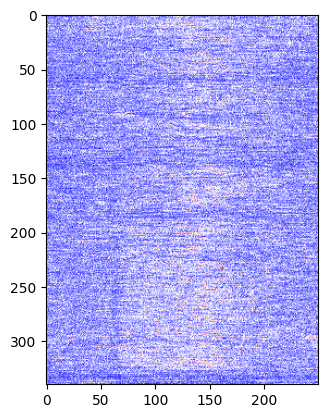

In [ ]:
mask = dset['brain_groups'] == 'thalamus'
pop_firing_rate = dset['spike_count'][mask,:,:].mean(axis=0)
plt.imshow(pop_firing_rate, cmap = 'bwr')

**Exercise**: From the spike counts, extract out all the trials and time points, but only the cells from the thalamus brain area. Plot the total spike counts across trials as a heat map.

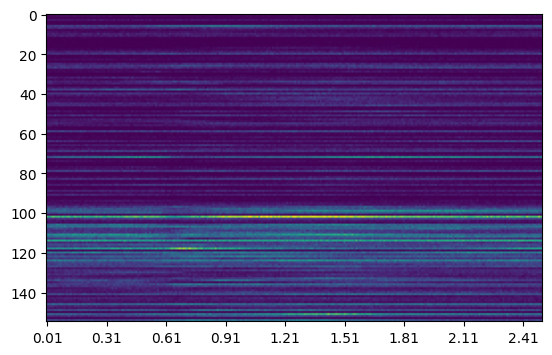

In [ ]:
time = dset['spike_count'].time.values
mask = dset['brain_groups'] == 'thalamus'
data = dset['spike_count'][mask, :, :]
total_spikes = data.sum(axis=1)
plt.imshow(total_spikes);
plt.xticks(np.arange(len(time))[::30], time[::30]);

**Exercise**: From the spike counts, extract out all the trials and time points, but only the cells from the Visual cortex brain area. Plot the total spike counts across trials as a heat map.

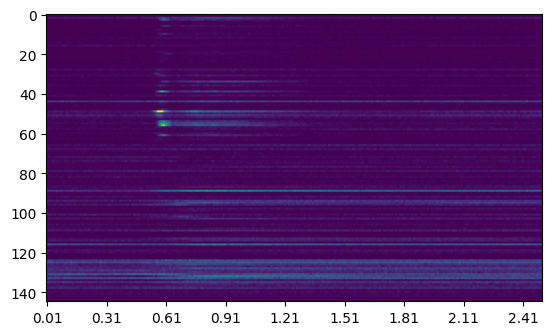

In [ ]:
mask = dset['brain_groups'] == 'visual cortex'
data = dset['spike_count'][mask, :, :]
total_spikes = data.sum(axis=1)
plt.imshow(total_spikes);
plt.xticks(np.arange(len(time))[::30], time[::30]);

**Exercise**: For each trial and time point, show the total activity across all cells in the visual cortex

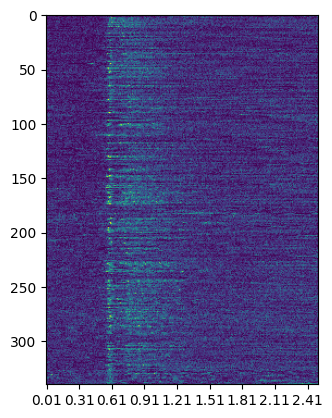

In [ ]:
mask = dset['brain_groups'] == 'visual cortex'
data = dset['spike_count'][mask, :, :]
total_spikes = data.sum(axis=0)
plt.imshow(total_spikes);
plt.xticks(np.arange(len(time))[::30], time[::30]);

**Exercise**: For each trial and time point, show the total activity across all cells in the hippocampus.

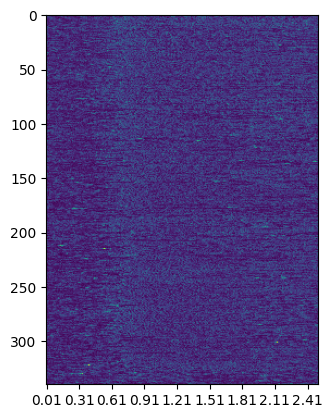

In [ ]:
mask = dset['brain_groups'] == 'hippocampus'
data = dset['spike_count'][mask, :, :]
total_spikes = data.sum(axis=0)
plt.imshow(total_spikes);
plt.xticks(np.arange(len(time))[::30], time[::30]);

**Example**: Make a line plot showing the average number of total spikes for all cells in the thalamus.

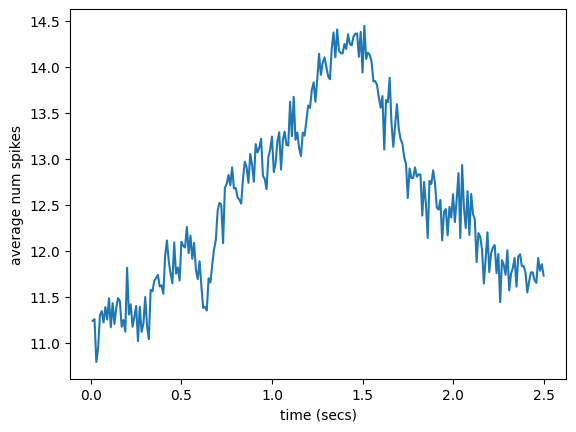

In [ ]:
mask = dset['brain_groups'] == 'thalamus'
data = dset['spike_count'][mask, :, :].sum(axis=0).mean(axis=0)
plt.plot(time, data);
plt.xlabel('time (secs)')
plt.ylabel('average num spikes');

**Exercise**: Make a line plot showing the average number of total spikes for all cells in the hippocampus.

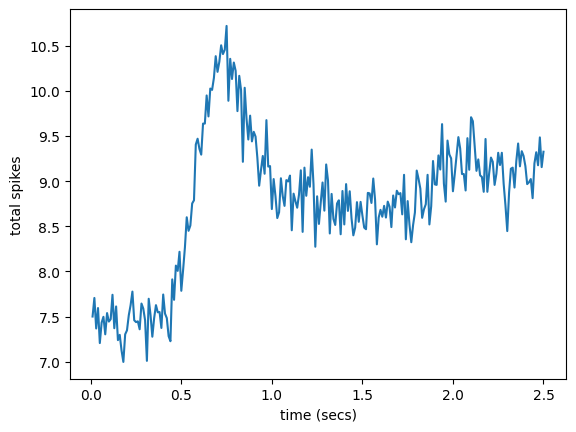

In [ ]:
mask = dset['brain_groups'] == 'hippocampus'
data = dset['spike_count'][mask, :, :].sum(axis=0).mean(axis=0)
plt.plot(time, data);
plt.xlabel('time (secs)')
plt.ylabel('total spikes');

**Exercise**: Make a line plot showing the average number of total spikes for all cells in the visual cortex.

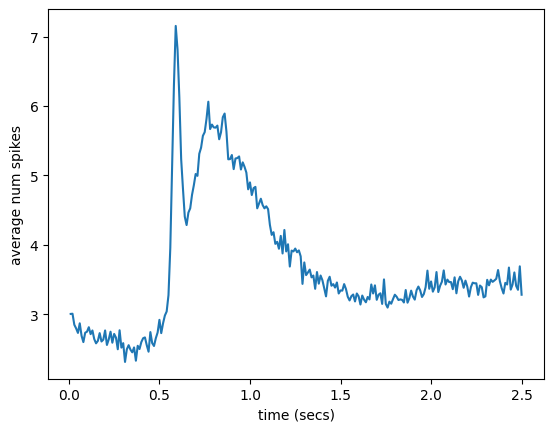

In [ ]:
mask = dset['brain_groups'] == 'visual cortex'
data = dset['spike_count'][mask, :, :].sum(axis=0).mean(axis=0)
plt.plot(time, data);
plt.xlabel('time (secs)')
plt.ylabel('average num spikes');

**Exercise**: Make a plot showing the average spike counts for all three brain areas (visual cortex, thalamus, and hippocampus)

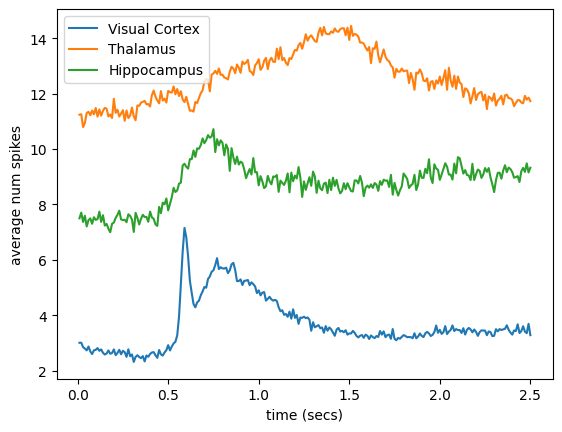

In [ ]:
mask = dset['brain_groups'] == 'visual cortex'
data = dset['spike_count'][mask, :, :].sum(axis=0).mean(axis=0)
plt.plot(time, data, label='Visual Cortex');

mask = dset['brain_groups'] == 'thalamus'
data = dset['spike_count'][mask, :, :].sum(axis=0).mean(axis=0)
plt.plot(time, data, label='Thalamus');

mask = dset['brain_groups'] == 'hippocampus'
data = dset['spike_count'][mask, :, :].sum(axis=0).mean(axis=0)
plt.plot(time, data, label='Hippocampus');

plt.xlabel('time (secs)')
plt.ylabel('average num spikes');
plt.legend();

## Demo: Simplifying this process using XArray

#### **Exercises**

**Example**: This can also be done without creating a bunch of variables.  Here are two examples:

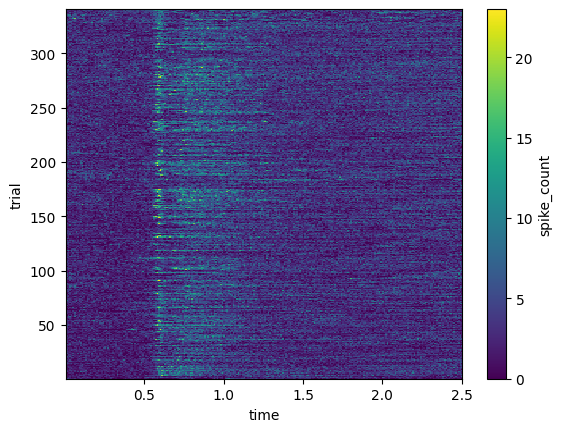

In [ ]:
dset['spike_count'][dset['brain_groups'] == 'visual cortex'].sum(dim='cell').plot.imshow();

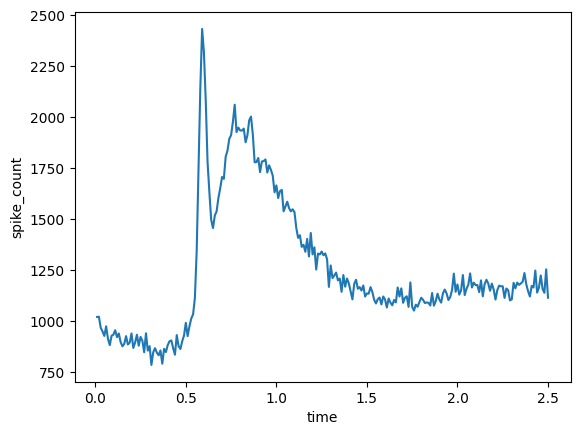

In [ ]:
dset['spike_count'][dset['brain_groups'] == 'visual cortex'].sum(dim=('cell', 'trial')).plot.line();